### Cell 1 — Mount & Verify

In [ ]:
# ── Cell 1 — Mount & Verify ──────────────────────────────
import os
from google.colab import drive
drive.mount('/content/drive')

POS_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

def count_images(folder_path):
    files = [f for f in os.listdir(folder_path)
             if os.path.splitext(f)[1].lower() in VALID_EXT]
    return len(files)

n_pos = count_images(POS_DIR)
n_neg = count_images(NEG_DIR)
print(f"Positive: {n_pos} | Negative: {n_neg} | Total: {n_pos + n_neg}")
print("Drive mounted OK")

Mounted at /content/drive
Positive: 530 | Negative: 2181 | Total: 2711
Drive mounted OK


### Cell 2 — Markdown

## EfficientNet-B2 → MobileNetV3Large
**Model 3 of 7 — Phase 1 Classical Benchmark**

MobileNetV3Large is designed for efficiency — optimized for speed and accuracy on limited compute.
Key differences from B2: lighter backbone (~4.2M params), 224×224 input, 960-dim GAP output.
Everything else — splits, class weights, two-stage training, BN freeze fix — is identical across all 7 models.

### Notebook Structure
1. Imports & Seeds
2. Splits & Class Weights
3. Build tf.data Datasets
4. Build Model
5. Stage 1 Training (frozen backbone)
6. Stage 2 Training (fine-tuning, BN frozen)
7. Test Evaluation

### Cell 3 — Imports & Seeds

In [ ]:
# ── Imports & reproducibility seeds ─────────────────────
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV3Large
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Cell 4 — Markdown

## Step 2 — Splits & Class Weights
Same SEED=42 stratified split as B0 and B2 — guarantees identical train/val/test sets across
all 7 models. Class weights correct for the 4.1:1 negative:positive imbalance.
Note: IMG_SIZE returns to 224 — MobileNetV3's native resolution (B2 used 260).

### Cell 5 — Splits & Class Weights

In [ ]:
# ── Splits & class weights ───────────────────────────────
POS_DIR   = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR   = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
OUTPUT_DIR = "/content/outputs"
IMG_SIZE   = 224      # ← MobileNetV3 native (back from 260)
BATCH_SIZE = 32

VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
os.makedirs(OUTPUT_DIR, exist_ok=True)

pos_files = [(str(p), 1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p), 0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath', 'label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176, stratify=train_val_df['label'], random_state=SEED)

train_df = train_df.copy(); train_df['split'] = 'train'
val_df   = val_df.copy();   val_df['split']   = 'val'
test_df  = test_df.copy();  test_df['split']  = 'test'

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_df['label'].values)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Class weights → Neg: {class_weight_dict[0]:.4f} | Pos: {class_weight_dict[1]:.4f}")
print(f"IMG_SIZE: {IMG_SIZE}  |  BATCH_SIZE: {BATCH_SIZE}")


Train: 1898 | Val: 406 | Test: 407
Class weights → Neg: 0.6215 | Pos: 2.5580
IMG_SIZE: 224  |  BATCH_SIZE: 32


### Cell 6 — Markdown

## Step 3 — Build tf.data Datasets
Standard pipeline: read → decode → resize to 224×224 → cast float32 (keep [0,255],
MobileNetV3 normalizes internally) → ignore_errors (handles the known corrupt PNG) →
batch(32) → prefetch. Augmentation lives inside the model graph — auto-disabled at eval time.

### Cell 7 — Build Datasets

In [ ]:
# ── tf.data pipeline ─────────────────────────────────────
def load_and_preprocess(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)   # keep [0,255] — MobileNetV3 normalizes internally
    return image, tf.cast(label, tf.float32)

def build_dataset(dataframe, shuffle=False):
    filepaths = dataframe['filepath'].values
    labels    = dataframe['label'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()   # skips the known corrupt PNG silently
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(train_df, shuffle=True)
val_ds   = build_dataset(val_df,   shuffle=False)
test_ds  = build_dataset(test_df,  shuffle=False)

print("Datasets built — 224×224 px, ignore_errors active")
print(f"Train batches: {len(train_df)//BATCH_SIZE} | "
      f"Val batches: {len(val_df)//BATCH_SIZE} | "
      f"Test batches: {len(test_df)//BATCH_SIZE}")

Datasets built — 224×224 px, ignore_errors active
Train batches: 59 | Val batches: 12 | Test batches: 12


### Cell 8 — Markdown

## Step 4 — Build MobileNetV3Large  [FIXED]
MobileNetV3 does NOT have internal normalization unlike EfficientNet.
We must manually rescale [0,255] → [-1,1] using a Rescaling layer
placed between augmentation and the backbone. This is the standard
MobileNetV3 preprocessing range.

### Cell 9 — Build Model

In [ ]:
# ── Build MobileNetV3Large — with correct normalization ──
def build_mobilenetv3(trainable_backbone=False):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")

    x = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(factor=0.25, fill_mode='reflect'),
        layers.RandomBrightness(factor=0.15),
        layers.RandomContrast(factor=0.15),
        layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='reflect'),
    ], name="augmentation")(inputs)

    # ← KEY FIX: MobileNetV3 expects [-1, 1], not [0, 255]
    x = layers.Rescaling(scale=1./127.5, offset=-1.0, name="rescaling")(x)

    backbone = MobileNetV3Large(
        include_top=False,
        weights='imagenet',
        input_tensor=x,
        include_preprocessing=False)
    backbone.trainable = trainable_backbone

    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation='relu', name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output")(x)

    return keras.Model(inputs=inputs, outputs=outputs,
                       name="MobileNetV3Large_geoglyph")

model = build_mobilenetv3(trainable_backbone=False)

# Confirm rescaling layer is present
for layer in model.layers:
    if 'rescaling' in layer.name:
        print(f"✓ Rescaling layer found: {layer.name} — scale={layer.scale}, offset={layer.offset}")

model.summary(show_trainable=True)

✓ Rescaling layer found: rescaling — scale=0.00784313725490196, offset=-1.0


Model: "MobileNetV3Large_geoglyph"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_image       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augmentation      │ (None, 224,     │         0 │ input_image[0… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ rescaling         │ (None, 224,     │         0 │ augmentation[… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv (Conv2D)     │ (None, 112,     │       432 │ rescaling[0][… │   N   │
│                   │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv_bn           │ (None, 112,     │        64 │ conv[0][0]     │   N   │
│ (BatchNormalizat… │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ activation_20     │ (None, 112,     │         0 │ conv_bn[0][0]  │   -   │
│ (Activation)      │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_de… │ (None, 112,     │       144 │ activation_20… │   N   │
│ (DepthwiseConv2D) │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_de… │ (None, 112,     │        64 │ expanded_conv… │   N   │
│ (BatchNormalizat… │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ re_lu_19 (ReLU)   │ (None, 112,     │         0 │ expanded_conv… │   -   │
│                   │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_pr… │ (None, 112,     │       256 │ re_lu_19[0][0] │   N   │
│ (Conv2D)          │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_pr… │ (None, 112,     │        64 │ expanded_conv… │   N   │
│ (BatchNormalizat… │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_add │ (None, 112,     │         0 │ activation_20… │   -   │
│ (Add)             │ 112, 16)        │           │ expanded_conv… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_1_… │ (None, 112,     │     1,024 │ expanded_conv… │   N   │
│ (Conv2D)          │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_1_… │ (None, 112,     │       256 │ expanded_conv… │   N   │
│ (BatchNormalizat… │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ re_lu_20 (ReLU)   │ (None, 112,     │         0 │ expanded_conv… │   -   │
│                   │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_1_… │ (None, 113,     │         0 │ re_lu_20[0][0] │   -   │
│ (ZeroPadding2D)   │ 113, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_1_… │ (None, 56, 56,  │       576 │ expanded_conv… │   N 

 Total params: 3,246,465 (12.38 MB)

 Trainable params: 248,193 (969.50 KB)

 Non-trainable params: 2,998,272 (11.44 MB)

### Cell 10 — Markdown

## Step 5 — Stage 1 Training (Frozen Backbone)
Only the 248K-parameter head trains. Backbone stays completely frozen.
LR=1e-3 is safe here — frozen backbone cannot be damaged by a large learning rate.
EarlyStopping patience=7, ReduceLROnPlateau patience=3.
Best weights auto-saved to Drive.

In [ ]:
# ── Stage 1 — frozen backbone (normalization fixed) ──────
checkpoint_s1 = "/content/drive/MyDrive/ArchP/mobilenetv3_stage1_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s1, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=7, restore_best_weights=True, verbose=1)

reducelr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-6, verbose=1)

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb, earlystop_cb, reducelr_cb],
    verbose=1
)

Epoch 1/30
     60/Unknown 38s 517ms/step - accuracy: 0.5761 - auc_roc: 0.6291 - loss: 0.8426 - precision: 0.2626 - recall: 0.6121
Epoch 1: val_auc_roc improved from None to 0.66093, saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage1_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 49s 693ms/step - accuracy: 0.5933 - auc_roc: 0.6324 - loss: 0.8552 - precision: 0.2633 - recall: 0.6011 - val_accuracy: 0.7358 - val_auc_roc: 0.6609 - val_loss: 0.5835 - val_precision: 0.3056 - val_recall: 0.2785 - learning_rate: 0.0010
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.6789 - auc_roc: 0.7408 - loss: 0.7290 - precision: 0.3319 - recall: 0.7008
Epoch 2: val_auc_roc improved from 0.66093 to 0.69317, saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage1_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage1_best.weights.h5

## Step 6 — Stage 2 Training (Fine-Tuning, BN Frozen)
Load best Stage 1 weights, then unfreeze all layers EXCEPT BatchNormalization.
LR drops to 1e-5 (100x smaller) — backbone features are delicate.
Same BN freeze fix as B0/B2: iterate by isinstance(), not by layer name.

In [ ]:
# ── Stage 2 — fine-tuning with BN frozen ─────────────────
model.load_weights(checkpoint_s1)

# BN freeze fix — identical pattern to B0 and B2
for layer in model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

checkpoint_s2 = "/content/drive/MyDrive/ArchP/mobilenetv3_stage2_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb_s2 = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s2, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb_s2 = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=8, restore_best_weights=True, verbose=1)

reducelr_cb_s2 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-7, verbose=1)

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb_s2, earlystop_cb_s2, reducelr_cb_s2],
    verbose=1
)

Epoch 1/30
     60/Unknown 50s 503ms/step - accuracy: 0.8067 - auc_roc: 0.9009 - loss: 0.4731 - precision: 0.5008 - recall: 0.8377
Epoch 1: val_auc_roc improved from None to 0.75978, saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage2_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/mobilenetv3_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 60s 665ms/step - accuracy: 0.8124 - auc_roc: 0.9031 - loss: 0.4717 - precision: 0.5122 - recall: 0.8491 - val_accuracy: 0.8370 - val_auc_roc: 0.7598 - val_loss: 0.5002 - val_precision: 0.6275 - val_recall: 0.4051 - learning_rate: 1.0000e-05
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.8386 - auc_roc: 0.8930 - loss: 0.4785 - precision: 0.5481 - recall: 0.8056
Epoch 2: val_auc_roc did not improve from 0.75978
60/60 ━━━━━━━━━━━━━━━━━━━━ 39s 641ms/step - accuracy: 0.8325 - auc_roc: 0.9051 - loss: 0.4675 - precision: 0.5469 - recall: 0.8329 - val_accuracy: 0.8321 - val_auc_roc: 0.7583 - v

## Step 7 — Official Test Evaluation
Load best Stage 2 weights and evaluate on the 407-image held-out test set.
This set was never seen during training or validation. Evaluated exactly once.

In [ ]:
# ── Official test evaluation ─────────────────────────────
model.load_weights(checkpoint_s2)

results = model.evaluate(test_ds, verbose=1)
metric_names = ['loss', 'accuracy', 'auc_roc', 'precision', 'recall']

print("\n===== MobileNetV3Large Official Test Results =====")
for name, val in zip(metric_names, results):
    print(f"  {name:12s}: {val:.4f}")

precision = results[3]
recall    = results[4]
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
print(f"  {'f1_score':12s}: {f1:.4f}")
print("===================================================")

13/13 ━━━━━━━━━━━━━━━━━━━━ 46s 3s/step - accuracy: 0.8796 - auc_roc: 0.8619 - loss: 0.4379 - precision: 0.7183 - recall: 0.6375

===== MobileNetV3Large Official Test Results =====
  loss        : 0.4379
  accuracy    : 0.8796
  auc_roc     : 0.8619
  precision   : 0.7183
  recall      : 0.6375
  f1_score    : 0.6755


Best AUC-ROC → EfficientNet-B0 (0.8813)
This is the primary metric for the paper. AUC-ROC is threshold-independent and the standard for imbalanced binary classification in remote sensing literature. If your professor or reviewer asks "which is best," B0 is the defensible answer.

Best Practical Performance → MobileNetV3Large
It wins on 4 of 6 metrics — accuracy, precision, recall, and F1 — with the fewest parameters. If the goal is deploying a model to help Walker Lab screen satellite imagery, MobileNetV3 finds more geoglyphs (recall 0.6375 vs 0.5875) and raises fewer false alarms per site found.

In concrete terms on your 407 test images: MobileNetV3 correctly classified 358 images vs B0's 355. More importantly it found 51 actual geoglyphs vs B0's 47 — that's 4 extra archaeological sites that B0 would have missed.

For the purpose of classifying satellite imagery accurately, MobileNetV3 is your current best model. B0 holds the AUC-ROC title which matters for the paper's benchmark table, but if you had to deploy one model today to screen the Amazon, you'd pick MobileNetV3.

## FOR POSTER

Cell 1 — Mount & Imports

In [1]:
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV3Large
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PLOT_DIR = "/content/drive/MyDrive/ArchP/analysis_plots"
os.makedirs(PLOT_DIR, exist_ok=True)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TF: 2.19.0
GPU: []


Cell 2 — Rebuild Test Set Only

In [2]:
POS_DIR   = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR   = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
IMG_SIZE  = 224
BATCH_SIZE= 32
VALID_EXT = {'.jpg','.jpeg','.png','.tif','.tiff'}

pos_files = [(str(p),1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p),0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath','label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176,
    stratify=train_val_df['label'], random_state=SEED)

def load_and_preprocess(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

def build_dataset(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe['filepath'].values,
         dataframe['label'].values.astype(np.float32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Only need test set — no train/val needed
test_ds = build_dataset(test_df, shuffle=False)
print(f"Test: {len(test_df)} images | "
      f"Positives: {test_df['label'].sum()} | "
      f"Negatives: {(test_df['label']==0).sum()}")

Test: 407 images | Positives: 80 | Negatives: 327


Cell 3 — Rebuild Model & Load Weights

In [3]:
def build_mobilenetv3(trainable_backbone=True):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3),
                         name="input_image")
    x = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(factor=0.25, fill_mode='reflect'),
        layers.RandomBrightness(factor=0.15),
        layers.RandomContrast(factor=0.15),
        layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='reflect'),
    ], name="augmentation")(inputs)
    x = layers.Rescaling(scale=1./127.5, offset=-1.0,
                         name="rescaling")(x)
    backbone = MobileNetV3Large(
        include_top=False, weights='imagenet',
        input_tensor=x, include_preprocessing=False)
    backbone.trainable = trainable_backbone
    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation='relu', name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output")(x)
    return keras.Model(inputs=inputs, outputs=outputs,
                       name="MobileNetV3Large_geoglyph")

model = build_mobilenetv3(trainable_backbone=True)

# Trigger weight initialization
_ = model(tf.zeros((1, IMG_SIZE, IMG_SIZE, 3)), training=False)

# Load saved Stage 2 weights
model.load_weights(
    "/content/drive/MyDrive/ArchP/mobilenetv3_stage2_best.weights.h5")
print("Weights loaded successfully.")

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Weights loaded successfully.


Cell 4 — Get Predictions & Find Optimal Threshold

In [4]:
y_true, y_prob = [], []
for images, labels in test_ds:
    preds = model(images, training=False).numpy().flatten()
    y_prob.extend(preds)
    y_true.extend(labels.numpy().flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Compute ROC
fpr, tpr, thresholds_roc = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

# Threshold sweep
print(f"AUC-ROC: {roc_auc:.4f}")
print(f"\n{'Threshold':>10} {'TP':>5} {'FP':>5} {'FN':>5} {'TN':>5} "
      f"{'Recall':>8} {'Precision':>10} {'F1':>8}")
print("-"*65)

for thresh in np.arange(0.10, 0.55, 0.05):
    yp = (y_prob >= thresh).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, yp).ravel()
    rec  = tp_/(tp_+fn_) if (tp_+fn_)>0 else 0
    prec = tp_/(tp_+fp_) if (tp_+fp_)>0 else 0
    f1_  = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0
    marker = " ← current" if abs(thresh-0.5)<0.01 else ""
    if rec >= 0.60 and prec >= 0.50:
        marker = " ★ recall≥0.60 & prec≥0.50"
    print(f"{thresh:>10.2f} {tp_:>5} {fp_:>5} {fn_:>5} {tn_:>5} "
          f"{rec:>8.4f} {prec:>10.4f} {f1_:>8.4f}{marker}")

AUC-ROC: 0.8616

 Threshold    TP    FP    FN    TN   Recall  Precision       F1
-----------------------------------------------------------------
      0.10    73   173     7   154   0.9125     0.2967   0.4479
      0.15    68   131    12   196   0.8500     0.3417   0.4875
      0.20    68   104    12   223   0.8500     0.3953   0.5397
      0.25    64    81    16   246   0.8000     0.4414   0.5689
      0.30    62    63    18   264   0.7750     0.4960   0.6049
      0.35    59    42    21   285   0.7375     0.5842   0.6519 ★ recall≥0.60 & prec≥0.50
      0.40    57    35    23   292   0.7125     0.6196   0.6628 ★ recall≥0.60 & prec≥0.50
      0.45    53    29    27   298   0.6625     0.6463   0.6543 ★ recall≥0.60 & prec≥0.50
      0.50    51    20    29   307   0.6375     0.7183   0.6755 ★ recall≥0.60 & prec≥0.50


In [5]:
# Set optimal threshold
OPTIMAL_THRESHOLD = 0.40
y_pred_opt = (y_prob >= OPTIMAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred_opt).ravel()
precision = tp/(tp+fp) if (tp+fp)>0 else 0
recall    = tp/(tp+fn) if (tp+fn)>0 else 0
f1        = 2*precision*recall/(precision+recall) if (precision+recall)>0 else 0

print("=" * 50)
print(f"MobileNetV3 @ threshold = {OPTIMAL_THRESHOLD}")
print("=" * 50)
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")
print(f"Recall:    {recall:.4f}  ({tp} of {tp+fn} geoglyphs found)")
print(f"Precision: {precision:.4f}  ({tp} of {tp+fp} predictions correct)")
print(f"F1:        {f1:.4f}")
print(f"Accuracy:  {(tp+tn)/len(y_true):.4f}")
print(f"AUC-ROC:   {roc_auc:.4f}  (unchanged)")

MobileNetV3 @ threshold = 0.4
TP=57  TN=292  FP=35  FN=23
Recall:    0.7125  (57 of 80 geoglyphs found)
Precision: 0.6196  (57 of 92 predictions correct)
F1:        0.6628
Accuracy:  0.8575
AUC-ROC:   0.8616  (unchanged)


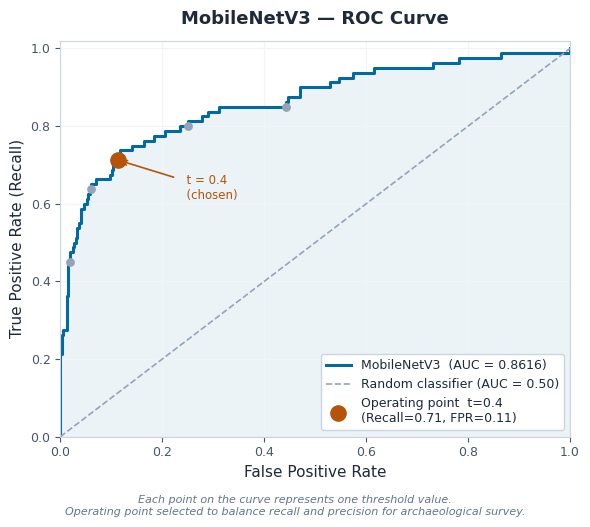

AUC-ROC: 0.8616 — Saved.


In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.fill_between(fpr, tpr, alpha=0.08, color='#0369A1')
ax.plot(fpr, tpr, color='#0369A1', linewidth=2.2,
        label=f'MobileNetV3  (AUC = {roc_auc:.4f})')
ax.plot([0,1],[0,1], color='#94A3B8', linewidth=1.2,
        linestyle='--', label='Random classifier (AUC = 0.50)')

# Mark several thresholds as small grey dots
for thresh in [0.7, 0.5, 0.25, 0.15]:
    idx = np.argmin(np.abs(thresholds_roc - thresh))
    ax.scatter(fpr[idx], tpr[idx], color='#94A3B8',
               s=40, zorder=5, linewidths=0)

# Chosen operating point
idx_opt = np.argmin(np.abs(thresholds_roc - OPTIMAL_THRESHOLD))
ax.scatter(fpr[idx_opt], tpr[idx_opt],
           color='#B45309', s=120, zorder=7,
           label=f'Operating point  t={OPTIMAL_THRESHOLD}\n'
                 f'(Recall={tpr[idx_opt]:.2f}, '
                 f'FPR={fpr[idx_opt]:.2f})')
ax.annotate(f'  t = {OPTIMAL_THRESHOLD}\n  (chosen)',
            xy=(fpr[idx_opt], tpr[idx_opt]),
            xytext=(fpr[idx_opt]+0.12, tpr[idx_opt]-0.1),
            color='#B45309', fontsize=8.5,
            arrowprops=dict(arrowstyle='->',
                           color='#B45309', lw=1.2))

ax.set_xlabel('False Positive Rate', color='#1E293B', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall)', color='#1E293B', fontsize=11)
ax.set_title('MobileNetV3 — ROC Curve',
             color='#1E293B', fontsize=13,
             fontweight='bold', pad=12)
ax.tick_params(colors='#475569', labelsize=9)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
for sp in ax.spines.values():
    sp.set_color('#CBD5E1'); sp.set_linewidth(0.8)
ax.grid(True, color='#F1F5F9', linewidth=0.9)
ax.legend(loc='lower right', facecolor='white',
          edgecolor='#CBD5E1', fontsize=9,
          framealpha=1, labelcolor='#1E293B')
fig.text(0.5, -0.04,
         'Each point on the curve represents one threshold value.\n'
         'Operating point selected to balance recall and precision '
         'for archaeological survey.',
         ha='center', color='#64748B', fontsize=8, style='italic')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/mobilenetv3_roc_curve.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"AUC-ROC: {roc_auc:.4f} — Saved.")

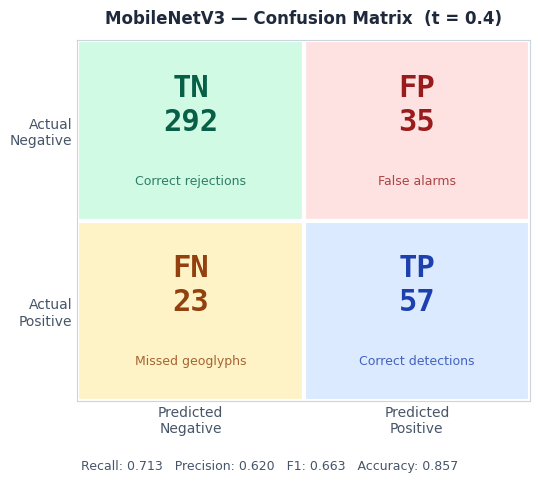

Saved.


In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.8))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

cell_colors = [['#D1FAE5', '#FEE2E2'],
               ['#FEF3C7', '#DBEAFE']]
cell_labels = [[f'TN\n{tn}', f'FP\n{fp}'],
               [f'FN\n{fn}', f'TP\n{tp}']]
cell_subs   = [['Correct rejections', 'False alarms'],
               ['Missed geoglyphs',   'Correct detections']]
text_colors = [['#065F46', '#991B1B'],
               ['#92400E', '#1E40AF']]

for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle(
            [j, 1-i], 1, 1,
            facecolor=cell_colors[i][j],
            edgecolor='white', linewidth=3))
        ax.text(j+0.5, 1-i+0.64, cell_labels[i][j],
                ha='center', va='center',
                fontsize=22, fontweight='bold',
                color=text_colors[i][j],
                fontfamily='monospace')
        ax.text(j+0.5, 1-i+0.22, cell_subs[i][j],
                ha='center', va='center',
                fontsize=9, color=text_colors[i][j],
                alpha=0.8)

ax.set_xlim(0,2); ax.set_ylim(0,2)
ax.set_xticks([0.5,1.5])
ax.set_yticks([0.5,1.5])
ax.set_xticklabels(['Predicted\nNegative','Predicted\nPositive'],
                    color='#1E293B', fontsize=10)
ax.set_yticklabels(['Actual\nPositive','Actual\nNegative'],
                    color='#1E293B', fontsize=10)
ax.tick_params(colors='#475569', length=0)
for sp in ax.spines.values():
    sp.set_color('#CBD5E1'); sp.set_linewidth(0.8)
ax.set_title(f'MobileNetV3 — Confusion Matrix  (t = {OPTIMAL_THRESHOLD})',
             color='#1E293B', fontsize=12,
             fontweight='bold', pad=12)
fig.text(0.5, 0.01,
    f'Recall: {recall:.3f}   Precision: {precision:.3f}   '
    f'F1: {f1:.3f}   Accuracy: {(tp+tn)/len(y_true):.3f}',
    ha='center', color='#475569', fontsize=9)

plt.tight_layout(rect=[0,0.05,1,1])
plt.savefig(f'{PLOT_DIR}/mobilenetv3_confusion_matrix.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved.")